# Customer Feedback Analysis and Automated Response

Project Overview
This project analyzes customer reviews to find unhappy customers (1-star and 2-star ratings), checks the most common complaints, and uses Gemini AI to write personalized apology emails for the 3 most critical reviews.

#### Dataset:
Women's E-Commerce Clothing Reviews (Kaggle)

    - The dataset contains 23,486 customer reviews.
    - Important columns used: Review Text (the customer's review) and Rating (from 1 to 5).
    - Link: https://www.kaggle.com/datasets/nicapotato/womens-ecommerce-clothing-reviews

## Import libraries
Import NumPy, Pandas, Matplotlib and Seaborn, which are used for data handling and charts.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## Load the dataset
Read the CSV file into a Pandas DataFrame and show the first 5 rows.

In [2]:
file_name = "Womens Clothing E-Commerce Reviews.csv"

df = pd.read_csv(file_name)

df.head()


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


### Understand the data
Check the columns, data types and how many values are missing in each column.

In [3]:
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Unnamed: 0               23486 non-null  int64
 1   Clothing ID              23486 non-null  int64
 2   Age                      23486 non-null  int64
 3   Title                    19676 non-null  str  
 4   Review Text              22641 non-null  str  
 5   Rating                   23486 non-null  int64
 6   Recommended IND          23486 non-null  int64
 7   Positive Feedback Count  23486 non-null  int64
 8   Division Name            23472 non-null  str  
 9   Department Name          23472 non-null  str  
 10  Class Name               23472 non-null  str  
dtypes: int64(6), str(5)
memory usage: 9.5 MB


Unnamed: 0                    0
Clothing ID                   0
Age                           0
Title                      3810
Review Text                 845
Rating                        0
Recommended IND               0
Positive Feedback Count       0
Division Name                14
Department Name              14
Class Name                   14
dtype: int64

## Columns that we want
Keep only the 4 columns needed for this project: Title, Review Text, Rating and Recommended IND.

In [4]:
df = df[["Title", "Review Text", "Rating", "Recommended IND"]].copy()

df.head()


,Title,Review Text,Rating,Recommended IND
0,NaN,Absolutely wonderful - silky and sexy and comf...,4,1
1,NaN,Love this dress! it's sooo pretty. i happene...,5,1
2,Some major design flaws,I had such high hopes for this dress and reall...,3,0
3,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1
4,Flattering shirt,This shirt is very flattering to all due to th...,5,1


##  Handle missing values

Fill missing Title and Review Text with empty text, then remove rows that have no review text.

In [5]:
df["Title"] = df["Title"].fillna("")
df["Review Text"] = df["Review Text"].fillna("")

df = df[df["Review Text"] != ""].copy()

print("Rows after handling missing review text:", df.shape[0])


Rows after handling missing review text: 22641


## Clean the review text
Convert the review to lowercase and remove punctuation marks, and save it in a new column called Clean Review.

In [6]:
df["Clean Review"] = df["Review Text"].str.lower()

punctuation = [".", ",", "!", "?", ":", ";", "(", ")", "[", "]", "{", "}", "/", "\\", "-", "_", "'", '"']

for mark in punctuation:
    df["Clean Review"] = df["Clean Review"].str.replace(mark, " ", regex=False)

df["Clean Review"] = df["Clean Review"].str.replace("  ", " ", regex=False)
df["Clean Review"] = df["Clean Review"].str.strip()

df[["Review Text", "Clean Review"]].head()


,Review Text,Clean Review
0,Absolutely wonderful - silky and sexy and comf...,absolutely wonderful silky and sexy and comfo...
1,Love this dress! it's sooo pretty. i happene...,love this dress it s sooo pretty i happened ...
2,I had such high hopes for this dress and reall...,i had such high hopes for this dress and reall...
3,"I love, love, love this jumpsuit. it's fun, fl...",i love love love this jumpsuit it s fun flirty...
4,This shirt is very flattering to all due to th...,this shirt is very flattering to all due to th...


## Identify Critical reviews
Reviews with a rating of 1 or 2 are treated as critical reviews. This cell collects them in one table.

In [7]:
critical_reviews = df[df["Rating"].isin([1, 2])].copy()

print("Total critical reviews:", critical_reviews.shape[0])

pd.set_option("display.max_colwidth", None)

critical_reviews.head(10)


Total critical reviews: 2370


,Title,Review Text,Rating,Recommended IND,Clean Review
5,Not for the very petite,"I love tracy reese dresses, but this one is not for the very petite. i am just under 5 feet tall and usually wear a 0p in this brand. this dress was very pretty out of the package but its a lot of dress. the skirt is long and very full so it overwhelmed my small frame. not a stranger to alterations, shortening and narrowing the skirt would take away from the embellishment of the garment. i love the color and the idea of the style but it just did not work on me. i returned this dress.",2,0,i love tracy reese dresses but this one is not for the very petite i am just under 5 feet tall and usually wear a 0p in this brand this dress was very pretty out of the package but its a lot of dress the skirt is long and very full so it overwhelmed my small frame not a stranger to alterations shortening and narrowing the skirt would take away from the embellishment of the garment i love the color and the idea of the style but it just did not work on me i returned this dress
22,Not what it looks like,"First of all, this is not pullover styling. there is a side zipper. i wouldn't have purchased it if i knew there was a side zipper because i have a large bust and side zippers are next to impossible for me.\n\nsecond of all, the tulle feels and looks cheap and the slip has an awkward tight shape underneath.\n\nnot at all what is looks like or is described as. sadly will be returning, but i'm sure i will find something to exchange it for!",2,0,first of all this is not pullover styling there is a side zipper i wouldn t have purchased it if i knew there was a side zipper because i have a large bust and side zippers are next to impossible for me \n\nsecond of all the tulle feels and looks cheap and the slip has an awkward tight shape underneath \n\nnot at all what is looks like or is described as sadly will be returning but i m sure i will find something to exchange it for
26,Huge disappointment,I have been waiting for this sweater coat to ship for weeks and i was so excited for it to arrive. this coat is not true to size and made me look short and squat. the sleeves are very wide (although long). as a light weight fall coat the sleeves don't need to be as wide because you wouldn't be layerng too much underneath. the buttons need to be moved at least three inches in for a nicer fit. i thought about redoing the buttons myself but the sleeves looked even more out of proportion with a tigh,2,0,i have been waiting for this sweater coat to ship for weeks and i was so excited for it to arrive this coat is not true to size and made me look short and squat the sleeves are very wide although long as a light weight fall coat the sleeves don t need to be as wide because you wouldn t be layerng too much underneath the buttons need to be moved at least three inches in for a nicer fit i thought about redoing the buttons myself but the sleeves looked even more out of proportion with a tigh
33,Mehh,"I ordered this 3 months ago, and it finally came off back order. a huge disappointment. the fit wasn&#39;t so much the issue for me. the quality of the wool is subpar. someone else mentioned a &quot;felted wool&quot;...i guess, is that what you call it? it does literally feel like felt! super thin, itchy, doesn&#39;t drape very well, and feels cheap (made in china). i got it on sale, but still not worth what i paid. definitely going back.",2,0,i ordered this 3 months ago and it finally came off back order a huge disappointment the fit wasn&#39 t so much the issue for me the quality of the wool is subpar someone else mentioned a &quot felted wool&quot i guess is that what you call it it does literally feel like felt super thin itchy doesn&#39 t drape very well and feels cheap made in china i got it on sale but still not worth what i paid definitely going back
56,,"I am pregnant and i thought this would be a great sleep bra. it's soft and fits okay, but it has zero support or shape. i would 

## Rating distribution
Count how many reviews were given for each rating from 1 to 5.

In [8]:
rating_count = df["Rating"].value_counts().sort_index()

rating_count


Rating
1      821
2     1549
3     2823
4     4908
5    12540
Name: count, dtype: int64

## Rating distribution chart

Bar chart showing the number of reviews for each rating.

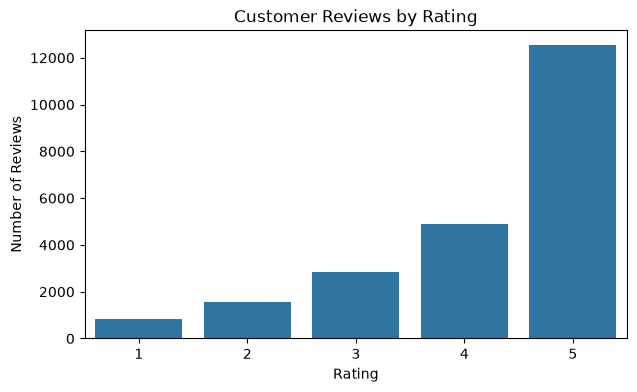

In [9]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Rating")
plt.title("Customer Reviews by Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()


## Common complaint keywords
Search the critical reviews for common complaint words (like size, quality, fit, refund) and count how many reviews contain each word.

In [10]:
keywords = "broken|damaged|late|delivery|shipping|refund|return|rude|quality|poor|wrong|size|small|large|fit|cheap|disappointed|customer service"

critical_reviews["complaints"] = critical_reviews["Clean Review"].str.contains(
    keywords,
    case=False,
    regex=True
)

keyword_counts = {}

for keyword in keywords.split("|"):
    count = critical_reviews["Clean Review"].str.contains(
        keyword,
        case=False,
        regex=False
    ).sum()

    keyword_counts[keyword] = count

keyword_table = pd.DataFrame(
    list(keyword_counts.items()),
    columns=["Keyword", "Count"]
)

keyword_table = keyword_table.sort_values(
    by="Count",
    ascending=False
)

keyword_table.head(20)


,Keyword,Count
14,fit,739
11,size,621
6,return,499
12,small,491
8,quality,312
13,large,310
16,disappointed,252
15,cheap,173
9,poor,91
10,wrong,59


## Top complaint keywords

Take the 10 most frequent complaint keywords from the table.

In [11]:
top_keywords = keyword_table.head(10)

print(top_keywords)


         Keyword  Count
14           fit    739
11          size    621
6         return    499
12         small    491
8        quality    312
13         large    310
16  disappointed    252
15         cheap    173
9           poor     91
10         wrong     59


## Top complaint keywords chart

Horizontal bar chart of the 10 most common complaint keywords.

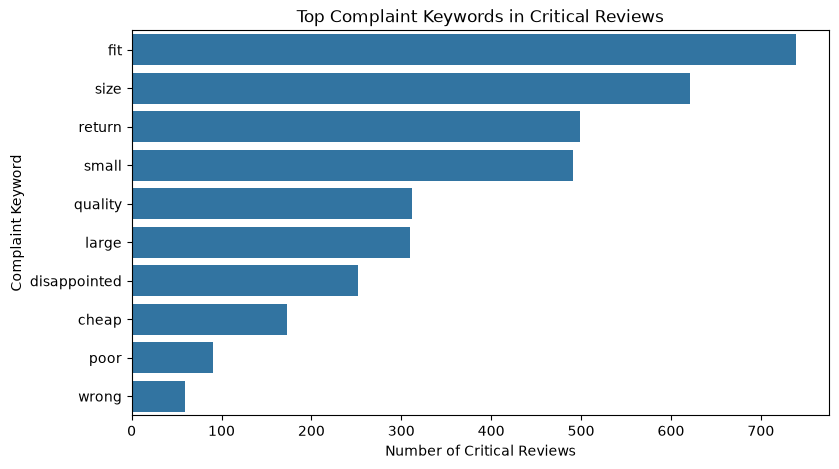

In [12]:
plt.figure(figsize=(9, 5))
sns.barplot(data=top_keywords, x="Count", y="Keyword")
plt.title("Top Complaint Keywords in Critical Reviews")
plt.xlabel("Number of Critical Reviews")
plt.ylabel("Complaint Keyword")
plt.show()


## 3 most critical negative reviews
Sort the critical reviews by length and pick the 3 longest ones, because they explain the problem in the most detail.

In [13]:
critical_reviews["Review Length"] = critical_reviews["Clean Review"].str.len()

top_3_reviews = critical_reviews.sort_values(
    "Review Length",
    ascending=False
).head(3).copy()

top_3_reviews[["Rating", "Title", "Review Text"]]


,Rating,Title,Review Text
12663,1,Runs small would be a bit of an understatement...,It is a shame when a product such as this is left on the website after so many comments reveal the item to be more defective in production than an opinion of size proportion. i read the reviews so had expected the item to run small so i ordered accordingly...this does not run small-this is not representative of any of the three categories one associates with women's apparel sizing. i am usually a small and the description by previous reviewers described the fit as being perfect for me-very small
10097,2,Poor quality for price,"I was really excited about this dress- the style looked like it would be a spring/summer staple in my retailer-heavy wardrobe. i was really surprised when i received it in the mail. the dress is quite thin cotton fabric and feels cheaply made. for the price, i could purchase a much higher quality dress elsewhere that would hold up better. i've been an retailer fan for more than an decade, but this trend of higher prices for lower quality is disappointing and insirpring me to leave a review for the f"
2106,2,Weird fit in the bust,I own many retailer dresses but the sizing can be odd. i usually wear a size 4-6 and i have a floreat maxi dress size 4 that works well. i am 34c and based on the reviews i decided to order a size 6. the dress fits well except for he bust area that is very snug/couldn't even get the zipper up. i will probably have to order a size 10 to be able to close the zipper on the bust area but it will be huge everywhere else.the fabric seems very delicate and may develop runs easily. it's a shame because th


## 3 selected reviews
Print the 3 selected reviews one by one with their rating and title.

In [14]:
for i in range(len(top_3_reviews)):
    print("=" * 70)
    print("Review", i + 1)
    print("Rating:", top_3_reviews.iloc[i]["Rating"])
    print("Title:", top_3_reviews.iloc[i]["Title"])
    print("Review:")
    print(top_3_reviews.iloc[i]["Review Text"])
    print()


Review 1
Rating: 1
Title: Runs small would be a bit of an understatement...
Review:
It is a shame when a product such as this is left on the website after so many comments reveal the item to be more defective in production than an opinion of size proportion. i read the reviews so had expected the item to run small so i ordered accordingly...this does not run small-this is not representative of any of the three categories one associates with women's apparel sizing. i am usually a small and the description by previous reviewers described the fit as being perfect for me-very small

Review 2
Rating: 2
Title: Poor quality for price
Review:
I was really excited about this dress- the style looked like it would be a spring/summer staple in my retailer-heavy wardrobe. i was really surprised when i received it in the mail. the dress is quite thin cotton fabric and feels cheaply made. for the price, i could purchase a much higher quality dress elsewhere that would hold up better. i've been an ret

## Automated apology emails
Ask for the Gemini API key. getpass hides the key so it is not shown in the notebook.

In [16]:
import requests
from getpass import getpass

api_key = getpass("Enter your Gemini API key: ")

print("API key available:", api_key is not None)


Enter your Gemini API key:  ········


API key available: True


## Function to generate the email

This function sends a review and its rating to Gemini with a prompt and returns the apology email text.

In [17]:
def generate_email(review, rating):

    url = "https://generativelanguage.googleapis.com/v1beta/models/gemini-3.5-flash-lite:generateContent"

    prompt = f"""Write a short and personalized apology email for this customer.
    Rating: {rating} stars
    Customer Review:{review}
    Requirements:
        - Start with a suitable subject line.
        - Apologize for the customer's experience.
        - Mention the main complaint.
        - Show empathy.
        - Keep it professional and simple.
        - Do not invent refunds or replacements.
        - End with a polite customer-support closing.
    """

    data = { "contents": 
             [{ "parts": 
              [{"text": prompt}
             ]}
             ]}

    response = requests.post(
        url,
        headers={"x-goog-api-key": api_key},
        json=data
    )

    result = response.json()

    return result["candidates"][0]["content"]["parts"][0]["text"]


## Generate the 3 response emails
Run the function on each of the 3 selected reviews and print the generated emails.

In [20]:
generated_emails = []

for i in range(len(top_3_reviews)):
    review = top_3_reviews.iloc[i]["Review Text"]
    rating = top_3_reviews.iloc[i]["Rating"]

    email = generate_email(review, rating)
    generated_emails.append(email)

    print("=" * 70)
    print("AI GENERATED EMAIL", i + 1)
    print(email)
    print()


AI GENERATED EMAIL 1
Subject: Regarding your recent order and sizing feedback

Dear Customer,

Please accept our sincere apologies for your disappointing experience with our apparel sizing. We are very sorry to hear that the item did not match the product description or the helpful feedback left by other shoppers, leaving you with a fit that was far from what you expected. 

We completely understand how frustrating it is to research a product beforehand, only for it to fall short of expectations, especially when dealing with inconsistent sizing. 

We truly appreciate you bringing this to our attention. Your feedback has been shared with our team to review how we can improve our product descriptions and better serve our customers moving forward. 

If there is anything else we can assist you with, please feel free to reach out.

Warm regards,

Customer Support Team

AI GENERATED EMAIL 2
Subject: We're sorry to hear about your experience with your new dress

Hi [Customer Name],

Thank you

## Final Project Insights
- The analysis helped identify critical customer reviews using low ratings, especially   1-star and 2-star reviews.

- The rating distribution helped understand the overall customer feedback pattern.

- Common complaint keywords were identified from the review text to understand the     main issues mentioned by customers.

- The most critical and detailed negative reviews were selected for further analysis.

- Gemini AI was used to generate personalized apology emails based on each customer's   review and rating.

- The generated responses mention the customer's main complaint, show empathy, and   maintain a professional tone.

- Overall, this project demonstrates how Python and Generative AI can be used together   to analyze customer feedback and automate customer-support responses.

## Conclusion
This project shows how customer reviews can be analyzed using Python to identify critical feedback and common complaints. Generative AI can then be used to create personalized responses, helping make the customer feedback analysis and response process more efficient.